# DST Sensor Fusion: Analysis & Supporting Figures

Companion notebook for:

> **Dempster-Shafer Theory-Based Sensor Fusion for Belief Quantification in
> Multi-Engine Network Intrusion Detection Systems** (submitted to *Sinkron*)

This repository ports the paper's DST fusion algorithm (`dst_fusion/`,
ported line-for-line from the production Go module in the Hyper-Parser
fusion package) to Python, and uses that port to:

1. sanity-check the ported code against the paper's reported belief values,
2. run it against **real** Snort/Suricata sample output (`data/fusible-sample/`),
3. reproduce the paper's **Table 2** (the 6,000-flow, three-mode PCAP test)
   from a calibrated synthetic dataset, since the original capture was never
   kept as a versioned artifact, only its aggregate results were, and
4. generate the figures used to visualize all of the above.

See `README.md` and `dst_fusion/simulate.py`'s module docstring for exactly
what is reconstructed vs. what is genuine sample data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dst_fusion import DST, HYP_TP, Correlator, belief, plausibility
from dst_fusion.loaders import load_fusible_sample
from dst_fusion.simulate import (
    DUAL_FLOWS, SNORT_ONLY_FLOWS, SURICATA_ONLY_FLOWS, UNMATCHED_DUAL_FLOWS,
    run_simulation,
)

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Palette kept consistent with the thesis's own figures (generate_figures.py)
C_SNORT    = "#2C5F8A"
C_SURICATA = "#4A9BC7"
C_FUSED    = "#3A7D7B"
C_SINGLE   = "#E8892B"
C_CONFLICT = "#C94040"
C_GRAY     = "#6B7280"
C_LGRAY    = "#E8EDF2"
C_DARK     = "#1F2937"

pd.set_option("display.width", 100)

## 1. DST core: sanity check against the paper

The paper reports Bel(TP) = 0.895 for a cross-engine fused Priority-2 event,
versus 0.665 (Snort alone) and 0.612 (Suricata alone) once each is combined
with the absent partner's silence mass. Everything below is computed live
from `dst_fusion.DST`, not hardcoded.

In [2]:
dst = DST()
snort_p2 = dst.alert_mass("snort", priority=2)
suricata_p2 = dst.alert_mass("suricata", priority=2)
silence = dst.silence()

fused, k_fused = dst.combine(snort_p2, suricata_p2)
snort_alone, k_sn = dst.combine(snort_p2, silence)
suricata_alone, k_su = dst.combine(suricata_p2, silence)

sanity = pd.DataFrame([
    {"scenario": "Snort P2 + Suricata P2 (fused)", "Bel(TP)": belief(fused, HYP_TP),
     "Pl(TP)": plausibility(fused, HYP_TP), "K": k_fused, "paper": 0.895},
    {"scenario": "Snort P2 alone (+ silence)", "Bel(TP)": belief(snort_alone, HYP_TP),
     "Pl(TP)": plausibility(snort_alone, HYP_TP), "K": k_sn, "paper": 0.665},
    {"scenario": "Suricata P2 alone (+ silence)", "Bel(TP)": belief(suricata_alone, HYP_TP),
     "Pl(TP)": plausibility(suricata_alone, HYP_TP), "K": k_su, "paper": 0.612},
]).round(3)
sanity

,scenario,Bel(TP),Pl(TP),K,paper
0,Snort P2 + Suricata P2 (fused),0.895,1.000,0.000,0.895
1,Snort P2 alone (+ silence),0.665,0.950,0.105,0.665
2,Suricata P2 alone (+ silence),0.612,0.942,0.098,0.612


## 2. BPA mass assignment per engine × priority

`DST.alert_mass()` scales each engine's base mass by alert priority
(P1 ×1.20, P2 ×1.00, P3 ×0.80, P4+ ×0.60, clamped to [0.05, 0.95]); the
remainder is assigned to Θ (ignorance), never to {FP}.

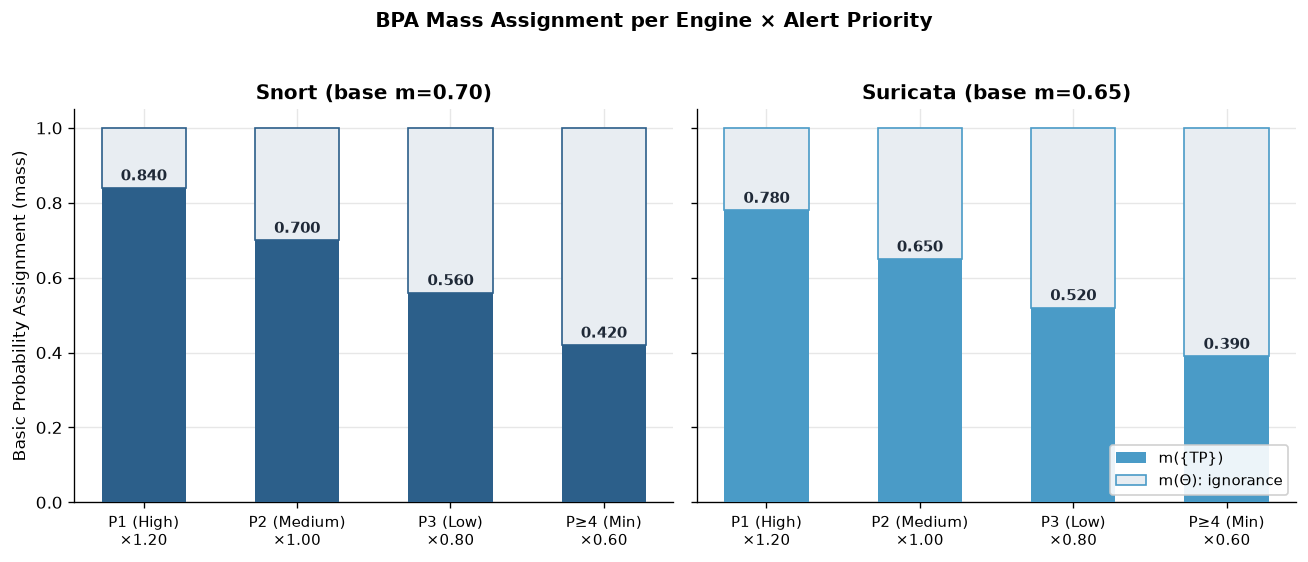

In [3]:
priorities = [1, 2, 3, 4]
labels = ["P1 (High)\n×1.20", "P2 (Medium)\n×1.00", "P3 (Low)\n×0.80", "P≥4 (Min)\n×0.60"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, engine, color in [(axes[0], "snort", C_SNORT), (axes[1], "suricata", C_SURICATA)]:
    m_tp = [dst.alert_mass(engine, p)[1] for p in priorities]  # HYP_TP == 1
    m_ign = [1.0 - v for v in m_tp]
    x = np.arange(len(priorities))
    ax.bar(x, m_tp, width=0.55, color=color, label="m({TP})", zorder=3)
    ax.bar(x, m_ign, width=0.55, bottom=m_tp, color=C_LGRAY, edgecolor=color,
           linewidth=1.0, label="m(Θ): ignorance", zorder=3)
    for xi, v in zip(x, m_tp):
        ax.text(xi, v + 0.02, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold", color=C_DARK)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_title(f"{engine.capitalize()} (base m={dst.engine_mass[engine]:.2f})", fontweight="bold")
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Basic Probability Assignment (mass)")
axes[1].legend(loc="lower right", fontsize=9, framealpha=0.9)
fig.suptitle("BPA Mass Assignment per Engine × Alert Priority", fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_bpa_mass_assignment.png")
plt.show()

## 3. Belief comparison across priority levels

The paper's headline figures (0.895 / 0.665 / 0.612) are the Priority-2
case. Extending the same computation across all four priority levels shows
the fused-vs-single gap holds throughout, widening at low priority where
uncorroborated single-engine evidence is punished hardest.

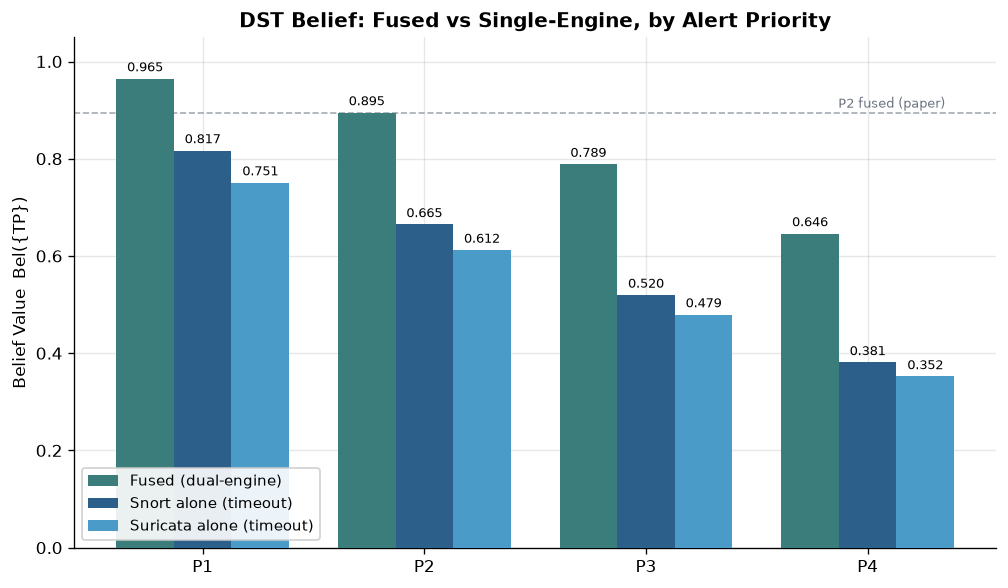

In [4]:
rows = []
for p in priorities:
    sm = dst.alert_mass("snort", p)
    um = dst.alert_mass("suricata", p)
    f, _ = dst.combine(sm, um)
    sa, _ = dst.combine(sm, silence)
    ua, _ = dst.combine(um, silence)
    rows.append({"priority": f"P{p}", "fused": belief(f, HYP_TP),
                  "snort_alone": belief(sa, HYP_TP), "suricata_alone": belief(ua, HYP_TP)})
belief_by_priority = pd.DataFrame(rows).set_index("priority")

fig, ax = plt.subplots(figsize=(8.5, 5))
x = np.arange(len(priorities))
w = 0.26
ax.bar(x - w, belief_by_priority["fused"], width=w, color=C_FUSED, label="Fused (dual-engine)", zorder=3)
ax.bar(x, belief_by_priority["snort_alone"], width=w, color=C_SNORT, label="Snort alone (timeout)", zorder=3)
ax.bar(x + w, belief_by_priority["suricata_alone"], width=w, color=C_SURICATA, label="Suricata alone (timeout)", zorder=3)
for xi, p in zip(x, priorities):
    for off, col in [(-w, "fused"), (0, "snort_alone"), (w, "suricata_alone")]:
        v = belief_by_priority.loc[f"P{p}", col]
        ax.text(xi + off, v + 0.015, f"{v:.3f}", ha="center", fontsize=7.5, rotation=90 if False else 0)
ax.axhline(0.895, color=C_GRAY, linestyle="--", linewidth=1, alpha=0.6)
ax.text(3.35, 0.905, "P2 fused (paper)", fontsize=8, color=C_GRAY, ha="right")
ax.set_xticks(x)
ax.set_xticklabels([f"P{p}" for p in priorities])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Belief Value  Bel({TP})")
ax.set_title("DST Belief: Fused vs Single-Engine, by Alert Priority", fontweight="bold")
ax.legend(loc="lower left", fontsize=9, framealpha=0.9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_belief_by_priority.png")
plt.show()

## 4. Real sample data: fusible test fixture walkthrough

`data/fusible-sample/` holds genuine Snort JSON-alert and Suricata EVE-JSON
output (synthetic content, real engine schema) from the Hyper-Parser
repository's own `test-data/fusible/` fixtures, purpose-built to exercise
cross-engine fusion (exact-duplicate SSH/SQL/DOS detections, one
complementary-evidence pair). Running it through the same `Correlator` used
throughout this notebook:

In [5]:
sample_alerts = load_fusible_sample("../data/fusible-sample")
sample_events = Correlator(window_seconds=5.0).process_stream(sample_alerts)

sample_df = pd.DataFrame([{
    "t (s)": round(e.ts - sample_events[0].ts, 3),
    "kind": e.kind,
    "engines": e.engines,
    "Bel(TP)": round(e.belief_tp, 3),
    "signature": e.signature,
} for e in sample_events]).sort_values("t (s)").reset_index(drop=True)
print(f"{len(sample_alerts)} raw alerts -> {len(sample_events)} events at the Defense Center")
sample_df

20 raw alerts -> 10 events at the Defense Center


,t (s),kind,engines,Bel(TP),signature
0,0.000,fused,snort+suricata,0.895,ET SCAN Potential SSH Scan
1,1.222,fused,snort+suricata,0.895,ET SCAN Potential SSH Scan OUTBOUND
2,1.988,fused,snort+suricata,0.846,ET SCAN Suspicious inbound to mySQL port 3306
3,2.099,fused,snort+suricata,0.846,ET SCAN Suspicious inbound to PostgreSQL port ...
4,2.210,fused,snort+suricata,0.846,ET SCAN Suspicious inbound to MSSQL port 1433
5,3.321,fused,snort+suricata,0.846,ET SCAN Potential VNC Scan 5800-5820
6,5.432,fused,snort+suricata,0.895,ET SCAN Potential SSH Scan
7,6.543,fused,snort+suricata,0.846,ET SCAN Suspicious inbound to SSL port 443
8,7.654,fused,snort+suricata,0.789,SURICATA ICMPv4 unknown code
9,10.765,fused,snort+suricata,0.934,DOS HTTP POST attack detected


## 5. Calibrated 6,000-flow simulation: reproducing Table 2

The paper's Table 2 comes from replaying a deterministic PCAP
(`nids_test.pcap`, 6,000 flows, 200 pps) through three pipeline modes; the
capture itself was never preserved, only the aggregate results. Rather than
fabricate a fake "original" dataset, `dst_fusion.simulate` back-solves a
flow-category composition **algebraically from Table 2's own four published
numbers** (Mode A, Mode B, Mode C, fusion rate; see the module docstring
for the derivation), generates a synthetic alert stream from that
composition, and replays it through the identical ported DST + correlation
code used in every section above. The numbers below are *computed*, not
copied from the paper.

In [6]:
sim = run_simulation()

table2 = pd.DataFrame([
    {"Mode": "A", "Configuration": "Snort only (blind to RDP)", "Events (paper)": 5000, "Events (this notebook)": sim.mode_a},
    {"Mode": "B", "Configuration": "Sidecar, without dedup", "Events (paper)": 10000, "Events (this notebook)": sim.mode_b},
    {"Mode": "C", "Configuration": "Hyper-Parser + DST fusion", "Events (paper)": 6047, "Events (this notebook)": sim.mode_c},
]).set_index("Mode")
print(f"Fusion rate: {sim.fusion_rate:.1%} (paper: 98.8%)")
print(f"Event reduction, C vs B: {sim.event_reduction_vs_mode_b:.1%} (paper: ~40%)")
print(f"Flow-category composition (back-solved): DUAL={DUAL_FLOWS} "
      f"(of which {UNMATCHED_DUAL_FLOWS} miss the correlation window), "
      f"SNORT_ONLY={SNORT_ONLY_FLOWS}, SURICATA_ONLY={SURICATA_ONLY_FLOWS} "
      f"-> {DUAL_FLOWS + SNORT_ONLY_FLOWS + SURICATA_ONLY_FLOWS} total flows "
      f"(paper: ~6,000)")
table2

Fusion rate: 98.8% (paper: 98.8%)
Event reduction, C vs B: 39.5% (paper: ~40%)
Flow-category composition (back-solved): DUAL=4001 (of which 48 miss the correlation window), SNORT_ONLY=999, SURICATA_ONLY=999 -> 5999 total flows (paper: ~6,000)


,Configuration,Events (paper),Events (this notebook)
Mode,,,
A,Snort only (blind to RDP),5000,5000
B,"Sidecar, without dedup",10000,10000
C,Hyper-Parser + DST fusion,6047,6047


## 6. Figure: event volume across the three pipeline modes

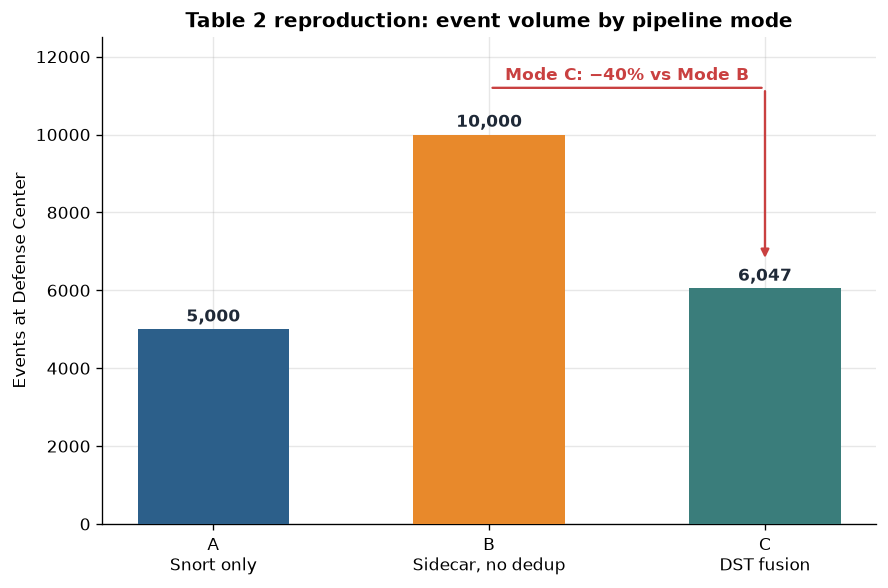

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5))
modes = ["A\nSnort only", "B\nSidecar, no dedup", "C\nDST fusion"]
values = [sim.mode_a, sim.mode_b, sim.mode_c]
colors = [C_SNORT, C_SINGLE, C_FUSED]
bars = ax.bar(modes, values, color=colors, width=0.55, zorder=3)
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 200, f"{v:,}", ha="center", fontweight="bold", color=C_DARK)
callout_y = max(values) * 1.12
ax.annotate("", xy=(2, callout_y), xytext=(1, callout_y),
            arrowprops=dict(arrowstyle="-", color=C_CONFLICT, lw=1.4))
ax.annotate("", xy=(2, sim.mode_c + 700), xytext=(2, callout_y),
            arrowprops=dict(arrowstyle="-|>", color=C_CONFLICT, lw=1.4))
ax.text(1.5, callout_y + max(values) * 0.02, f"Mode C: −{sim.event_reduction_vs_mode_b:.0%} vs Mode B",
        color=C_CONFLICT, fontweight="bold", ha="center", fontsize=10)
ax.set_ylabel("Events at Defense Center")
ax.set_title("Table 2 reproduction: event volume by pipeline mode", fontweight="bold")
ax.set_ylim(0, max(values) * 1.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_three_modes_comparison.png")
plt.show()

## 7. Figure: Mode C event composition (fusion outcome)

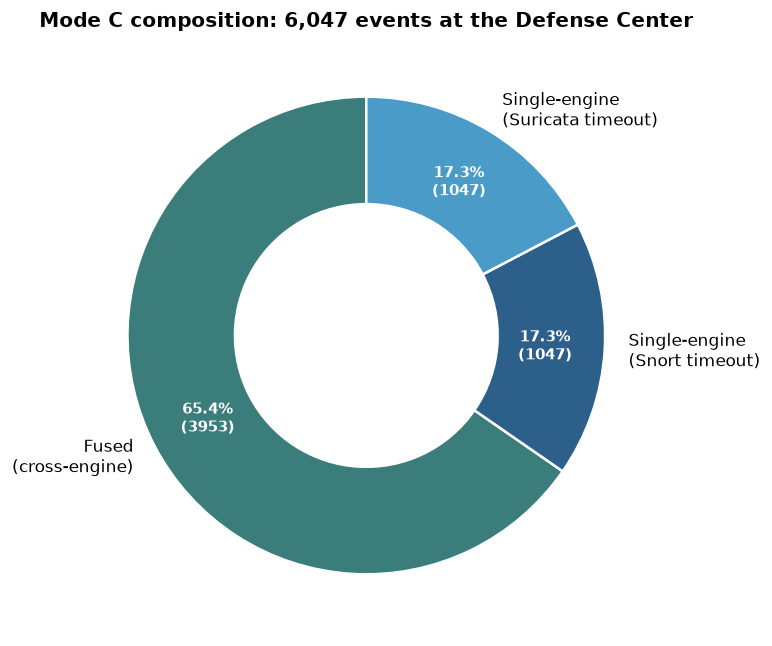

In [8]:
from collections import Counter
kind_counts = Counter(e.kind for e in sim.events)
order = ["fused", "single_snort", "single_suricata"]
kind_labels = {"fused": "Fused\n(cross-engine)", "single_snort": "Single-engine\n(Snort timeout)",
               "single_suricata": "Single-engine\n(Suricata timeout)"}
vals = [kind_counts[k] for k in order]
colors2 = [C_FUSED, C_SNORT, C_SURICATA]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, texts, autotexts = ax.pie(
    vals, labels=[kind_labels[k] for k in order], colors=colors2, autopct=lambda p: f"{p:.1f}%\n({p/100*sim.mode_c:.0f})",
    startangle=90, pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=1.5),
)
for t in autotexts:
    t.set_fontsize(9)
    t.set_color("white")
    t.set_fontweight("bold")
ax.set_title(f"Mode C composition: {sim.mode_c:,} events at the Defense Center", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_event_breakdown.png")
plt.show()

## 8. Figure: Bel(TP) distribution across all simulated events

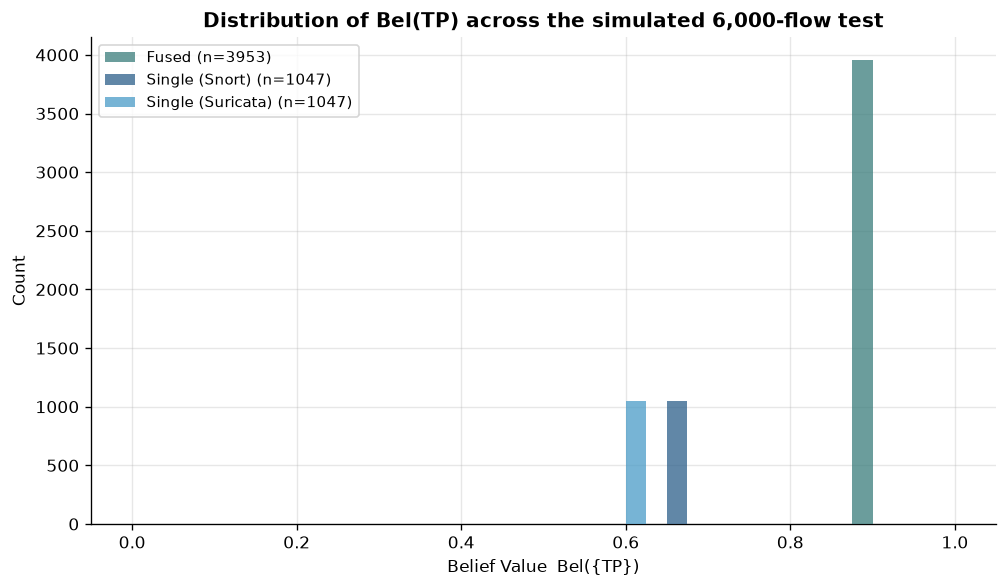

In [9]:
belief_df = pd.DataFrame([{"kind": e.kind, "belief_tp": e.belief_tp} for e in sim.events])
fig, ax = plt.subplots(figsize=(8.5, 5))
bins = np.linspace(0, 1, 41)
for k, color, label in [("fused", C_FUSED, "Fused"), ("single_snort", C_SNORT, "Single (Snort)"),
                         ("single_suricata", C_SURICATA, "Single (Suricata)")]:
    vals = belief_df.loc[belief_df["kind"] == k, "belief_tp"]
    ax.hist(vals, bins=bins, color=color, alpha=0.75, label=f"{label} (n={len(vals)})", zorder=3)
ax.set_xlabel("Belief Value  Bel({TP})")
ax.set_ylabel("Count")
ax.set_title("Distribution of Bel(TP) across the simulated 6,000-flow test", fontweight="bold")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_belief_distribution.png")
plt.show()

## Reproducibility

* All figures are regenerated by re-running this notebook top to bottom;
  nothing here is hand-edited after execution.
* `simulate.run_simulation()` uses a fixed seed (`DEFAULT_SEED = 20260327`),
  so results are deterministic across runs and machines.
* Section 5 onward is a **calibrated reconstruction** of Table 2, not the
  original experiment; see `dst_fusion/simulate.py`'s module docstring and
  `data/fusible-sample/README.md` for exactly what is genuine sample data
  vs. back-solved synthetic input, and why the original PCAP could not be
  used directly.
* Package versions are pinned in `uv.lock`; `uv sync && uv run jupyter
  notebook` reproduces this environment exactly.